In [1]:
import uproot
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [13]:
base = "/Users/PITLab/3D_sensors/Processed_data/"

filenames = [
    ("proc_Keysight_C_DJ100W50B9_bv120_mcp4400_trigExt_MCP_channel_only_10000_15mV.root", "proc_F_DJ100W50B9_strip3mm_bv120_mcp4400_trigExt_MCP_channel_only_10000_15mV.root"),
    ("proc_Keysight_C_DJ100W50B9_bv120_mcp4400_trigExt_MCP_channel_only_10000_10mV.root", "proc_F_DJ100W50B9_strip3mm_bv120_mcp4400_trigExt_MCP_channel_only_10000_10mV.root"),
    ("proc_Keysight_C_DJ100W50B9_bv120_mcp4400_trigExt_MCP_channel_only_10000_8mV.root", "proc_F_DJ100W50B9_strip3mm_bv120_mcp4400_trigExt_MCP_channel_only_10000_8mV.root"),
    ("proc_Keysight_C_DJ100W50B9_bv120_mcp4400_trigExt_MCP_channel_only_10000_6mV.root", "proc_F_DJ100W50B9_strip3mm_bv120_mcp4400_trigExt_MCP_channel_only_10000_6mV.root")
]

filenames = [
    ("proc_Keysight_C_DJ100W50B9_bv120_mcp4400_trigExtCh3_MCP_channel_only_10000_15mV.root", "proc_F_DJ100W50B9_strip3mm_bv120_mcp4400_trigExtCh3_MCP_channel_only_10000_15mV.root")
]

# djlgad_data = uproot.open(f"{base}/proc_C_DJ100W50B9_strip3mm_bv120_mcp4400_trigExt_MCP_channel_only_3000_DJLGAD.root")["pulse"].arrays()
# # mcp_data    = uproot.open(f"{base}/proc_F_DJ100W50B9_strip3mm_bv120_mcp4400_trigExt_MCP_channel_only_3000_MCP.root")   ["pulse"].arrays()

# djlgad_data = uproot.open(f"{base}/proc_Keysight_C_DJ100W50B9_bv120_mcp4400_trigExt_MCP_channel_only_3000_15mV.root")["pulse"].arrays()
# mcp_data    = uproot.open(f"{base}/proc_F_DJ100W50B9_strip3mm_bv120_mcp4400_trigExt_MCP_channel_only_3000_15mV.root")["pulse"].arrays()

# djlgad_data = uproot.open(f"{base}/proc_Keysight_C_DJ100W50B9_bv120_mcp4400_trigExt_MCP_channel_only_3000_13mV.root")["pulse"].arrays()
# mcp_data    = uproot.open(f"{base}/proc_F_DJ100W50B9_strip3mm_bv120_mcp4400_trigExt_MCP_channel_only_3000_13mV.root")["pulse"].arrays()

# djlgad_data = uproot.open(f"{base}/proc_Keysight_C_DJ100W50B9_bv120_mcp4400_trigExt_MCP_channel_only_10000_15mV.root")["pulse"].arrays()
# mcp_data    = uproot.open(f"{base}/proc_F_DJ100W50B9_strip3mm_bv120_mcp4400_trigExt_MCP_channel_only_10000_15mV.root")["pulse"].arrays()

# djlgad_data = uproot.open(f"{base}/proc_Keysight_C_DJ100W50B9_bv120_mcp4400_trigExt_MCP_channel_only_10000_10mV.root")["pulse"].arrays()
# mcp_data    = uproot.open(f"{base}/proc_F_DJ100W50B9_strip3mm_bv120_mcp4400_trigExt_MCP_channel_only_10000_10mV.root")["pulse"].arrays()

# djlgad_data = uproot.open(f"{base}/proc_Keysight_C_DJ100W50B9_bv120_mcp4400_trigExt_MCP_channel_only_10000_8mV.root")["pulse"].arrays()
# mcp_data    = uproot.open(f"{base}/proc_F_DJ100W50B9_strip3mm_bv120_mcp4400_trigExt_MCP_channel_only_10000_8mV.root")["pulse"].arrays()

# djlgad_data = uproot.open(f"{base}/proc_Keysight_C_DJ100W50B9_bv120_mcp4400_trigExt_MCP_channel_only_10000_6mV.root")["pulse"].arrays()
# mcp_data    = uproot.open(f"{base}/proc_F_DJ100W50B9_strip3mm_bv120_mcp4400_trigExt_MCP_channel_only_10000_6mV.root")["pulse"].arrays()

In [14]:
def gaussian(x, A, mu, sigma):
    return A * np.exp(- ((x - mu)**2) / (2 * sigma**2))

['i_evt', 'channel', 'time', 'baseline', 'baseline_RMS', 'noise', 'amp', 't_peak', 'integral', 'intfull', 'risetime', 'decaytime', 'LP2_5', 'LP2_10', 'LP2_15', 'LP2_20', 'LP2_25', 'LP2_30', 'LP2_35', 'LP2_40', 'LP2_45', 'LP2_50', 'LP2_55', 'LP2_60', 'LP2_65', 'LP2_70', 'LP2_75', 'LP2_80', 'LP2_85', 'LP2_90', 'LP2_95', 'LP2_100', 'LP2_410mV', 'LP2_500mV', 'LP2_600mV', 'LP2_700mV', 'LP2_800mV', 'LP2_10mV', 'LP2_20mV', 'LP2_30mV', 'LP2_50mV', 'LP2_70mV', 'LP2_90mV', 'LP2_100mV', 'LP2_120mV', 'LP2_140mV', 'LP2_160mV', 'LP2_180mV', 'LP2_200mV', 'linear_RE_5', 'linear_RE_10', 'linear_RE_15', 'linear_RE_20', 'linear_RE_25', 'linear_RE_30', 'linear_RE_35', 'linear_RE_40', 'linear_RE_45', 'linear_RE_50', 'linear_RE_55', 'linear_RE_60', 'linear_RE_65', 'linear_RE_70', 'linear_RE_75', 'linear_RE_80', 'linear_RE_85', 'linear_RE_90', 'linear_RE_95', 'linear_RE_100', 'linear_RE__410mV', 'linear_RE__500mV', 'linear_RE__600mV', 'linear_RE__700mV', 'linear_RE__800mV', 'linear_RE__10mV', 'linear_RE__20m

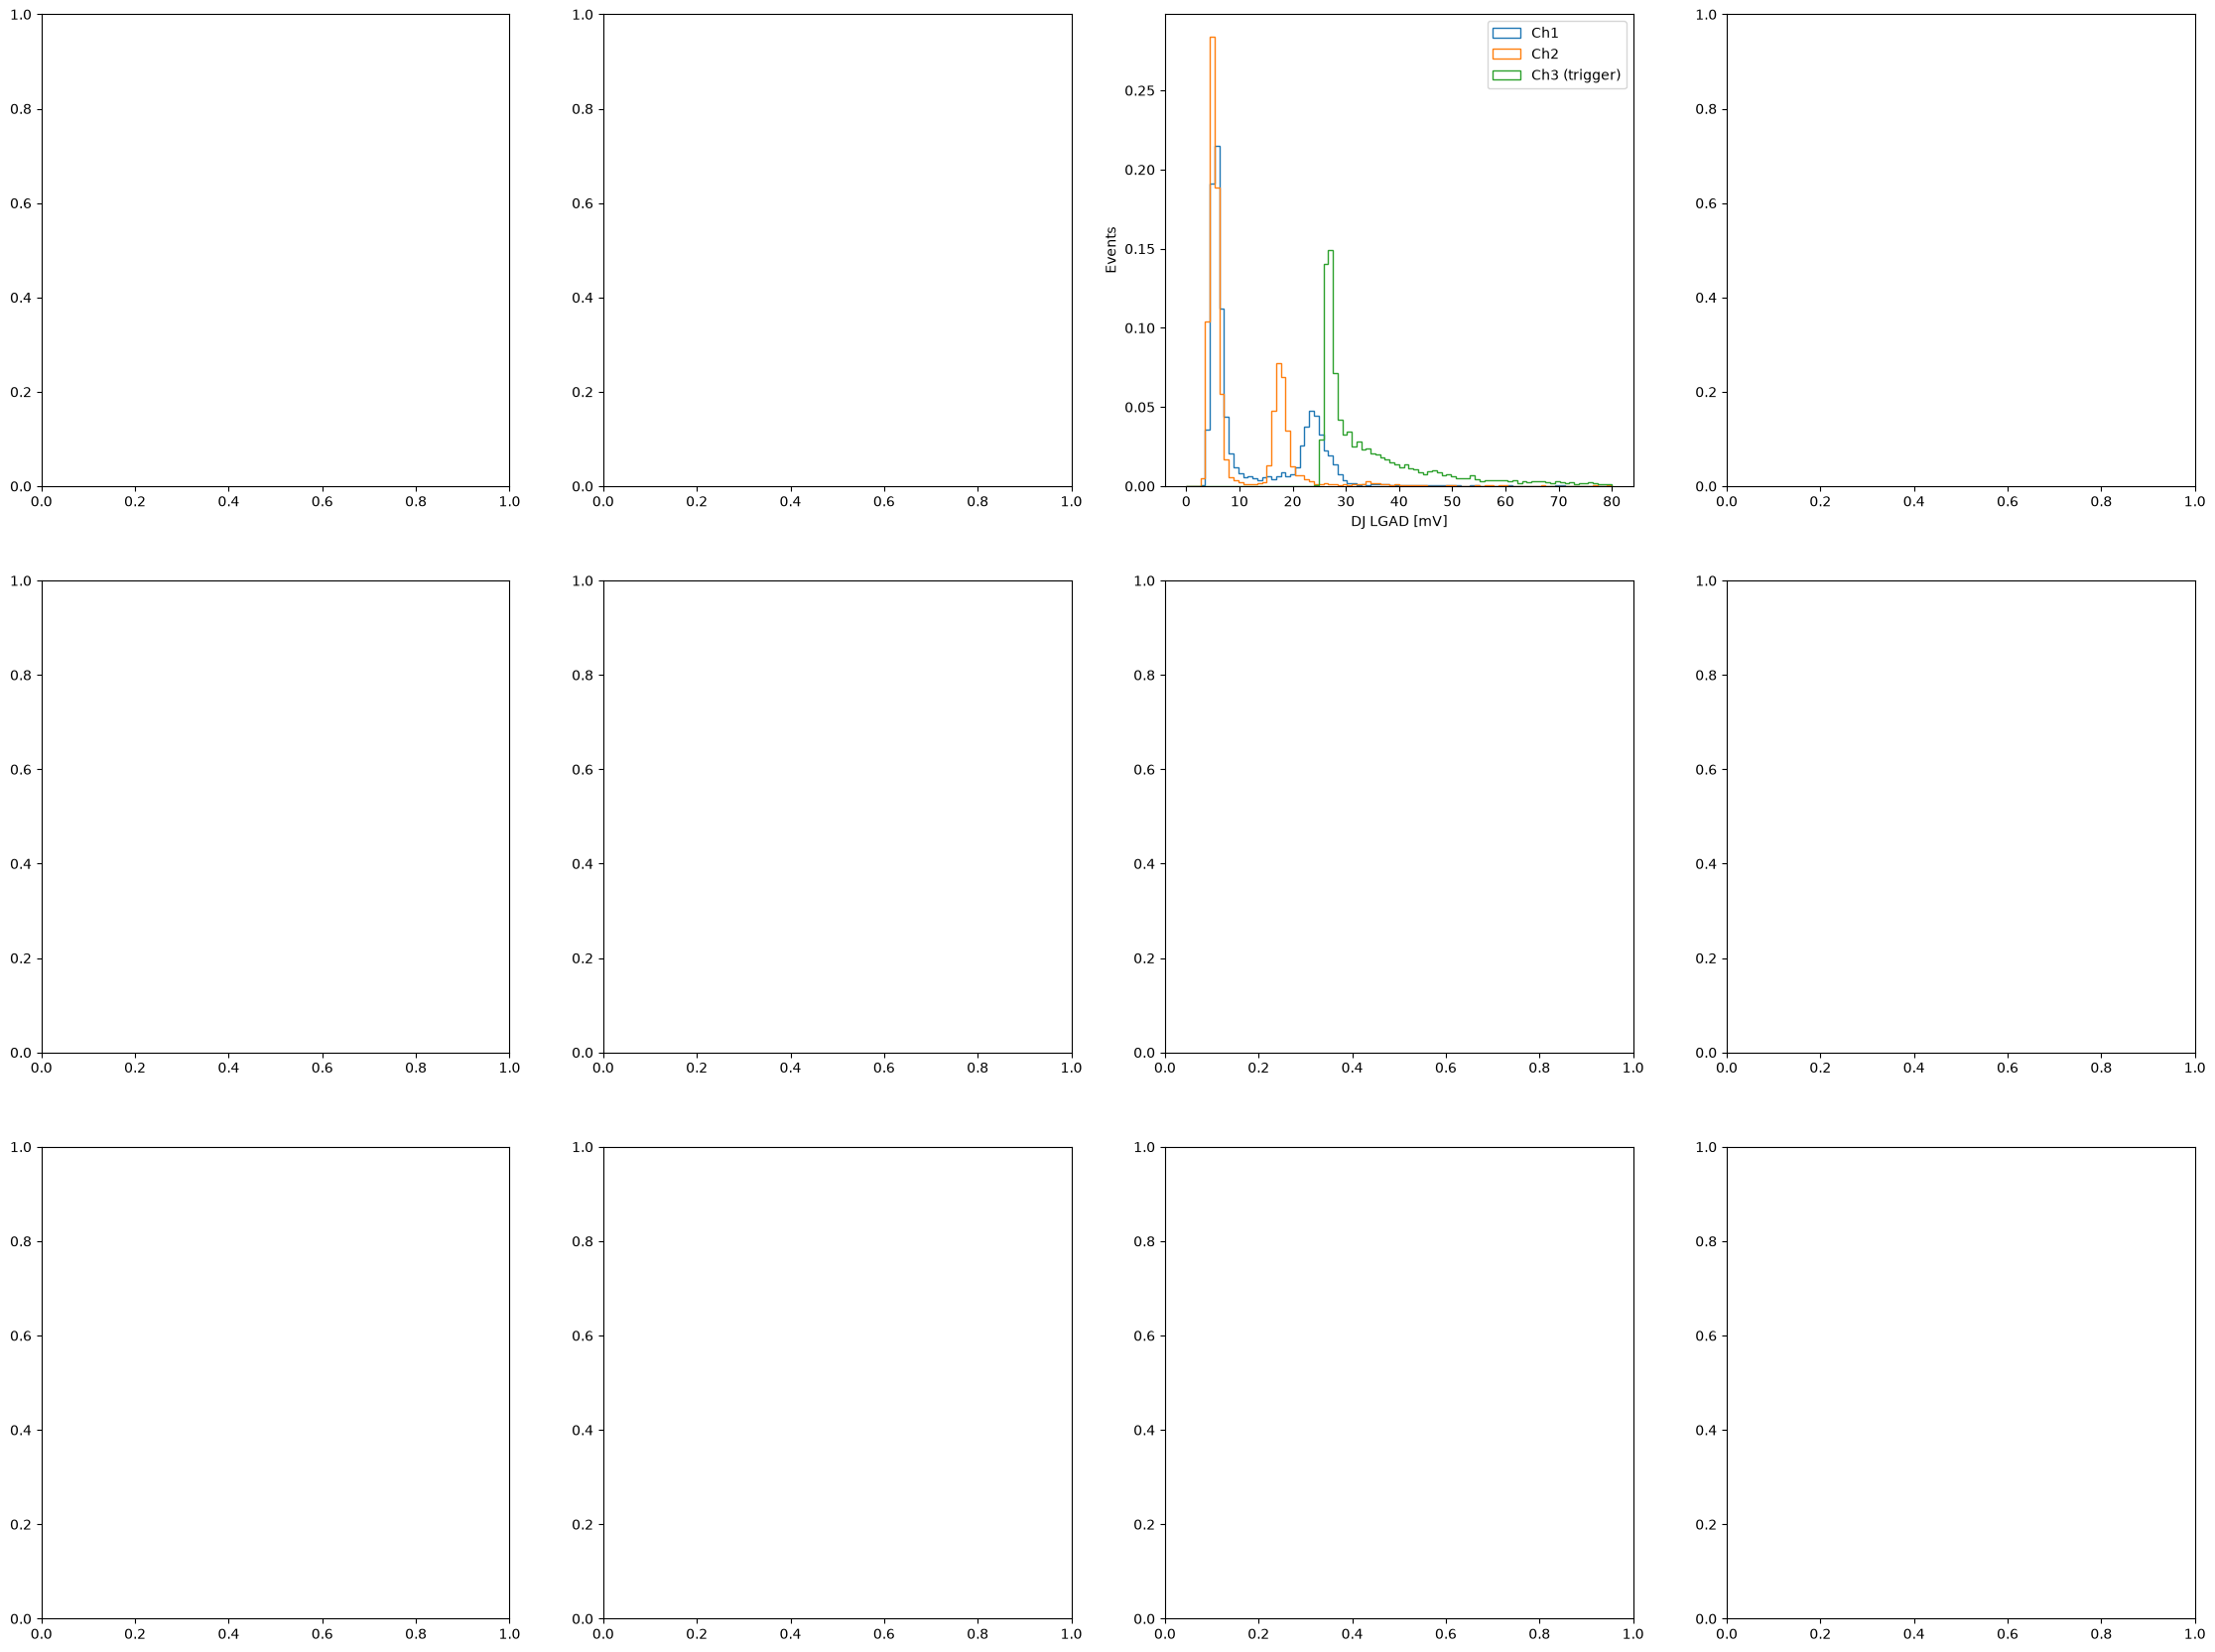

In [18]:
LEC_MCP_CHANNEL = 7
LEC_TRIGGER_CHANNEL = 6
KEY_LGAD_CHANNEL = 1

summary_resolution = []
summary_resolution_corr = []
summary_min_lgad_value = []

for filename_pair in filenames:

    djlgad_data = uproot.open(f"{base}/{filename_pair[0]}")["pulse"].arrays()
    mcp_data    = uproot.open(f"{base}/{filename_pair[1]}")["pulse"].arrays()

    print(mcp_data.fields)
    
    djlgad_time_axis    = djlgad_data["time"][:, 0]
    djlgad_channel_axis = djlgad_data["channel"][:, KEY_LGAD_CHANNEL]
    
    mcp_amp = mcp_data["amp"][:,LEC_MCP_CHANNEL]
    trigger_amp = mcp_data["amp"][:,LEC_TRIGGER_CHANNEL]
    djlgad_amp = djlgad_data["amp"][:,KEY_LGAD_CHANNEL]
    djlgad_right_amp = djlgad_data["amp"][:,KEY_LGAD_CHANNEL+1]
    djlgad_left_amp  = djlgad_data["amp"][:,KEY_LGAD_CHANNEL-1]
    
    mcp_time = mcp_data["LP2_50"][:,LEC_MCP_CHANNEL]
    trigger_time = mcp_data["LP2_50"][:,LEC_TRIGGER_CHANNEL]
    djlgad_time       = djlgad_data["LP2_50"][:,KEY_LGAD_CHANNEL]
    
    mcp_baseline_RMS = mcp_data["baseline_RMS"][:,LEC_MCP_CHANNEL]
    trigger_baseline_RMS = mcp_data["baseline_RMS"][:,LEC_TRIGGER_CHANNEL]
    djlgad_baseline_RMS = djlgad_data["baseline_RMS"][:,KEY_LGAD_CHANNEL]
    
    size = 7
    rows = 3
    cols = 4
    nbins = 90
    
    fit_x_axis_points = nbins
    poly_degree = 7
    
    cuts = np.ones(len(djlgad_time_axis), dtype = bool) # (djlgad_amp<80) # & (djlgad_baseline_RMS<3) & (djlgad_time>-0.5) & (djlgad_time<-0.3) & (djlgad_amp > djlgad_right_amp) & (djlgad_amp > djlgad_left_amp) #  & (mcp_time<-12) & (mcp_baseline_RMS<3) & (mcp_time<-21.8)

    # cuts = (djlgad_amp<80) & (mcp_time<-12) & (mcp_baseline_RMS<3) & (djlgad_baseline_RMS<3) & (mcp_time<-21.5) & (djlgad_time>-0.6) 
    # cuts = (djlgad_amp<80) & (mcp_time<-12) & (mcp_baseline_RMS<3) & (djlgad_baseline_RMS<3) & (mcp_time>-22.2) & (djlgad_time>-0.6) 
    
    fig, ax = plt.subplots(rows,cols, figsize = (cols*size, rows*size))
    
    # ax[0][0].hist(mcp_amp    [cuts], bins = nbins, histtype  = "step") # , range = (0, 100))
    # ax[0][0].set_xlabel("MCP amp [mV]")
    # ax[0][0].set_ylabel("Events")
    
    # ax[0][1].hist(trigger_amp[cuts], bins = nbins, histtype  = "step")
    # ax[0][1].set_xlabel("Trigger signal [mV]")
    # ax[0][1].set_ylabel("Events")
    
    weights = np.ones(len(djlgad_amp[cuts])) / len(djlgad_amp[cuts])
    ax[0][2].hist(djlgad_left_amp [cuts], bins = nbins, histtype  = "step", label = "Ch1", weights = weights, range = (0, 80)) # , range = (0, 100))
    ax[0][2].hist(djlgad_amp      [cuts], bins = nbins, histtype  = "step", label = "Ch2", weights = weights, range = (0, 80)) # , range = (0, 100))
    ax[0][2].hist(djlgad_right_amp[cuts], bins = nbins, histtype  = "step", label = "Ch3 (trigger)", weights = weights, range = (0, 80)) # , range = (0, 100))
    ax[0][2].legend()
    ax[0][2].set_xlabel("DJ LGAD [mV]")
    ax[0][2].set_ylabel("Events")
    
    # for i in range(len(djlgad_amp[cuts])):
    #     ax[0][3].plot(djlgad_time_axis[cuts][i], djlgad_channel_axis[cuts][i])
    # ax[0][3].set_xlim(-1,1)
    # ax[0][3].set_xlabel("Time [ns]")
    # ax[0][3].set_ylabel("Voltage [ns]")
    
    # ax[1][0].hist(mcp_time    [cuts], bins = nbins, histtype  = "step")
    # ax[1][0].set_xlabel("MCP timestamp [ns]")
    # ax[1][0].set_ylabel("Events")
    
    # # ax[1][1].hist(trigger_time[cuts], bins = nbins, histtype  = "step")
    # # ax[1][1].set_xlabel("Trigger timestamp [ns]")
    # # ax[1][1].set_ylabel("Events")
    
    # ax[1][2].hist(djlgad_time [cuts], bins = nbins, histtype  = "step")
    # ax[1][2].set_xlabel("DJ-LGAD timestamp [ns]")
    # ax[1][2].set_ylabel("Events")
    
    # n_sigma = 2
    # DT = mcp_time[cuts] - djlgad_time[cuts]
    # counts, bins, patches = ax[2][0].hist(DT, bins = nbins, histtype = "step")
    # mean = np.mean(DT)
    # std = np.std(DT)
    # x_axis = bins[0:nbins] # np.linspace(min(DT), max(DT), fit_x_axis_points) # mean-n_sigma*std, mean+n_sigma*std, len(counts[fit_x_range]))
    # fit_x_range = (bins[0:nbins]>mean-n_sigma*std)&(bins[0:nbins]<mean+n_sigma*std)

    # params = curve_fit(gaussian, bins[0:nbins][fit_x_range], counts[fit_x_range], p0 = (np.max(counts), np.mean(bins), np.std(bins)))
    # y_axis = [gaussian(x, params[0][0], params[0][1], params[0][2]) for x in bins[0:nbins][fit_x_range]]
    
    # fit_label = f"Fit: \n Amp: {np.round(params[0][0],2)}, \n mean: {np.round(params[0][1],2)}, \n sigma:{np.round(1000*params[0][2],2)}."
    # ax[2][0].plot(x_axis[fit_x_range]+(x_axis[fit_x_range][1]-x_axis[fit_x_range][0])/2, y_axis, color = "red", label = fit_label, marker = "o")
    # ax[2][0].legend()
    # ax[2][0].set_xlabel("Delta T [ns]")
    # ax[2][0].set_ylabel("Events")
    
    # # counts, bins, patches = 
    # ax[2][1].scatter(djlgad_amp[cuts], DT)
    # fit_params = np.polyfit(djlgad_amp[cuts], DT, poly_degree)
    # x_axis = np.linspace(np.min(djlgad_amp[cuts]), np.max(djlgad_amp[cuts]), fit_x_axis_points)
    # fit_line = np.polyval(fit_params, x_axis)
    # fit_label = "Fit: \n"
    # for i, par in enumerate(fit_params):
    #     fit_label += f" par{i}={np.round(par,7)}, \n"
    # ax[2][1].set_xlabel("Delta T [ns]")
    # ax[2][1].set_ylabel("DJ-LGAD amplitude [mV]")
    # ax[2][1].plot(
    #     x_axis,
    #     fit_line,
    #     '-',
    #     label=fit_label, 
    #     color = "red",
    #     marker = "o"
    # )
    # ax[2][1].legend()
    
    # n_sigma = 2
    # DT_corr = DT - np.polyval(fit_params, djlgad_amp[cuts])
    # counts, bins, patches = ax[2][2].hist(DT_corr, bins = nbins, histtype  = "step")
    # mean = np.mean(DT_corr)
    # std = np.std(DT_corr)
    # x_axis = bins[0:nbins] # np.linspace(min(DT_corr), max(DT_corr), fit_x_axis_points) # np.linspace(mean-n_sigma*std, mean+n_sigma*std, len(counts[fit_x_range]))
    # fit_x_range = (bins[0:nbins]>mean-n_sigma*std)&(bins[0:nbins]<mean+n_sigma*std)
    
    # params = curve_fit(gaussian, bins[0:nbins][fit_x_range], counts[fit_x_range], p0 = (np.max(counts), np.mean(bins), np.std(bins)))
    # y_axis = [gaussian(x, params[0][0], params[0][1], params[0][2]) for x in bins[0:nbins][fit_x_range]]
    
    # fit_label = f"Fit: \n Amp: {np.round(params[0][0],2)}, \n mean: {np.round(params[0][1],2)}, \n sigma:{np.round(1000*params[0][2],2)}."
    # ax[2][2].plot(x_axis[fit_x_range]+(x_axis[fit_x_range][1]-x_axis[fit_x_range][0])/2, y_axis, color = "red", label = fit_label, marker = "o")
    # ax[2][2].set_xlabel("Delta T (corrected) [ns]")
    # ax[2][2].set_ylabel("Events")
    # ax[2][2].legend()
    
    plt.show()
    fig.savefig(f"./Output_plots/DataOverview_{filename_pair[0].split('_')[-1].split('.root')[0]}.png")


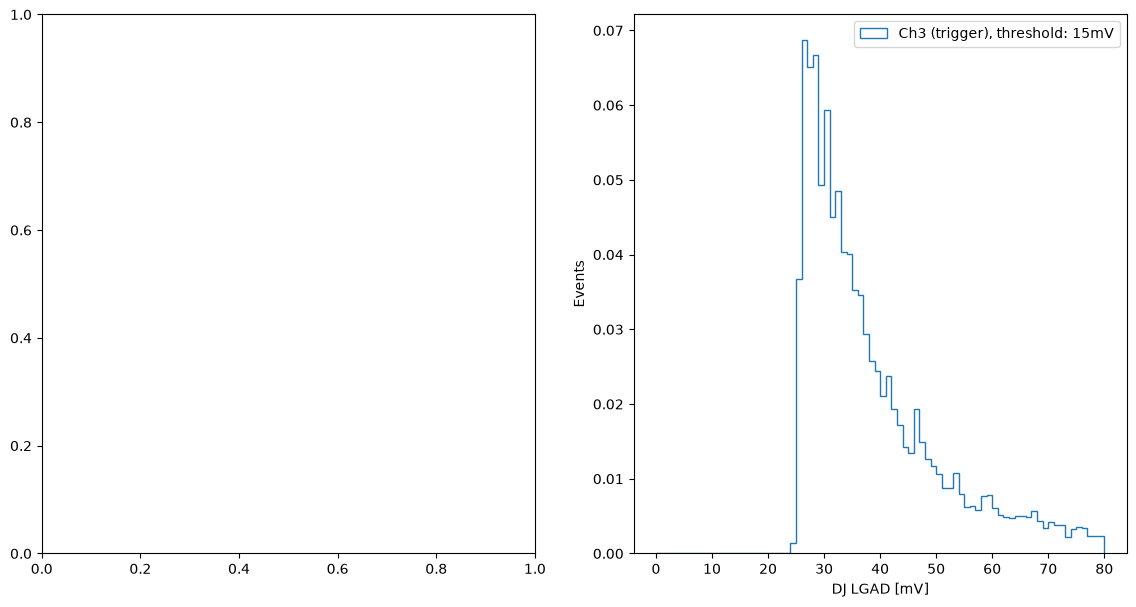

In [32]:
LEC_MCP_CHANNEL = 7
LEC_TRIGGER_CHANNEL = 6
KEY_LGAD_CHANNEL = 2

summary_resolution = []
summary_resolution_corr = []
summary_min_lgad_value = []

rows = 1
cols = 2
nbins = 20

fig, ax = plt.subplots(rows, cols, figsize = (cols*size, rows*size))

for filename_pair in filenames:

    djlgad_data = uproot.open(f"{base}/{filename_pair[0]}")["pulse"].arrays()
    mcp_data    = uproot.open(f"{base}/{filename_pair[1]}")["pulse"].arrays()
    
    djlgad_time_axis    = djlgad_data["time"][:, 0]
    djlgad_channel_axis = djlgad_data["channel"][:, KEY_LGAD_CHANNEL]
    
    mcp_amp = mcp_data["amp"][:,LEC_MCP_CHANNEL]
    trigger_amp = mcp_data["amp"][:,LEC_TRIGGER_CHANNEL]
    
    djlgad_amp = djlgad_data["amp"][:,2]
    djlgad_right_amp = djlgad_data["amp"][:,0]
    djlgad_left_amp  = djlgad_data["amp"][:,1]
    
    mcp_time = mcp_data["LP2_50"][:,LEC_MCP_CHANNEL]
    trigger_time = mcp_data["LP2_50"][:,LEC_TRIGGER_CHANNEL]
    djlgad_time = djlgad_data["LP2_50"][:,KEY_LGAD_CHANNEL]
    
    mcp_baseline_RMS = mcp_data["baseline_RMS"][:,LEC_MCP_CHANNEL]
    trigger_baseline_RMS = mcp_data["baseline_RMS"][:,LEC_TRIGGER_CHANNEL]
    djlgad_baseline_RMS = djlgad_data["baseline_RMS"][:,KEY_LGAD_CHANNEL]
    
    size = 7
    rows = 3
    cols = 4
    nbins = 80
    
    fit_x_axis_points = nbins
    poly_degree = 7
    
    cuts = (djlgad_amp<80) & (djlgad_baseline_RMS<3) # & (djlgad_time>-0.5) & (djlgad_time<-0.3) & (djlgad_amp > djlgad_right_amp) & (djlgad_amp > djlgad_left_amp) #  & (mcp_time<-12) & (mcp_baseline_RMS<3) & (mcp_time<-21.8)

    # cuts = (djlgad_amp<80) & (mcp_time<-12) & (mcp_baseline_RMS<3) & (djlgad_baseline_RMS<3) & (mcp_time<-21.5) & (djlgad_time>-0.6) 
    # cuts = (djlgad_amp<80) & (mcp_time<-12) & (mcp_baseline_RMS<3) & (djlgad_baseline_RMS<3) & (mcp_time>-22.2) & (djlgad_time>-0.6) 
        
    # ax[0][0].hist(mcp_amp    [cuts], bins = nbins, histtype  = "step") # , range = (0, 100))
    # ax[0][0].set_xlabel("MCP amp [mV]")
    # ax[0][0].set_ylabel("Events")
    
    # ax[0][1].hist(trigger_amp[cuts], bins = nbins, histtype  = "step")
    # ax[0][1].set_xlabel("Trigger signal [mV]")
    # ax[0][1].set_ylabel("Events")
    
    weights = np.ones(len(djlgad_amp[cuts])) / len(djlgad_amp[cuts])
    # ax[1].hist(djlgad_left_amp[cuts], bins = nbins, histtype  = "step", label = f"Ch1", weights = weights, range = (0, 80)) # , range = (0, 100))
    # ax[1].hist(djlgad_right_amp[cuts], bins = nbins, histtype  = "step", label = f"Ch2", weights = weights, range = (0, 80)) # , range = (0, 100))
    ax[1].hist(djlgad_amp[cuts], bins = nbins, histtype  = "step", label = f"Ch3 (trigger), threshold: {filename_pair[0].split("_")[-1].split(".root")[0]}", weights = weights, range = (0, 80)) # , range = (0, 100))
    ax[1].legend()
    ax[1].set_xlabel("DJ LGAD [mV]")
    ax[1].set_ylabel("Events")
    
plt.show()
# fig.savefig(f"./Output_plots/DataOverview_{filename_pair[0].split('_')[-1].split('.root')[0]}.png")


In [ ]:
n_sigma = 1

# print(bins[0:nbins][(bins[0:nbins]>mean-n_sigma*std)&(bins[0:nbins]<mean+n_sigma*std)])
# print(counts[(bins[0:nbins]>mean-n_sigma*std)&(bins[0:nbins]<mean+n_sigma*std)])

print(len(x_axis), x_axis)
print(len(fit_x_range), fit_x_range)
print(x_axis[fit_x_range])

In [95]:
mcp_amp = mcp_data["amp"][:,7]
trigger_amp = mcp_data["amp"][:,6]
djlgad_amp = djlgad_data["amp"][:,1]

mcp_time = mcp_data["LP2_50"][:,7]
trigger_time = mcp_data["LP2_50"][:,6]
djlgad_time = djlgad_data["LP2_50"][:,1]

mcp_baseline_RMS = mcp_data["baseline_RMS"][:,7]
trigger_baseline_RMS = mcp_data["baseline_RMS"][:,6]
djlgad_baseline_RMS = djlgad_data["baseline_RMS"][:,1]

print(len(mcp_amp), mcp_amp)
print(len(trigger_amp), trigger_amp)
print(len(trig_ch_amp), trig_ch_amp)

print(len(mcp_baseline_RMS), mcp_baseline_RMS)
print(len(trigger_baseline_RMS), trigger_baseline_RMS)
print(len(djlgad_baseline_RMS), djlgad_baseline_RMS)

size = 5
rows = 1
cols = 3
nbins = 80

cuts = (djlgad_amp<80) & (mcp_time<-12) & (mcp_baseline_RMS<3) & (djlgad_baseline_RMS<3)

fig, ax = plt.subplots(rows,cols, figsize = (cols*size, rows*size))

ax[0].hist2d(mcp_time    [cuts].to_list(), mcp_amp    [cuts].to_list(), bins = nbins) # , histtype  = "step")
ax[1].hist2d(trigger_time[cuts].to_list(), trigger_amp[cuts].to_list(), bins = nbins) #, bins = nbins) # , histtype  = "step")
ax[2].hist2d(djlgad_time [cuts].to_list(), djlgad_amp [cuts].to_list(), bins = nbins) #, bins = nbins) # , histtype  = "step")

# ax[1][0].hist(mcp_time    [cuts], bins = nbins, histtype  = "step")
# ax[1][1].hist(trigger_time[cuts], bins = nbins, histtype  = "step")
# ax[1][2].hist(djlgad_time [cuts], bins = nbins, histtype  = "step")

plt.show()


10000 [4.82, 32.7, 4.95, 5.78, 4.51, 4.61, ..., 7.84, 5.46, 5.18, 4.95, 4.48, 5.93]
10000 [1.69e+03, 1.69e+03, 1.69e+03, 1.7e+03, ..., 1.7e+03, 1.69e+03, 1.69e+03]


NameError: name 'trig_ch_amp' is not defined

<h2> Amplitudes </h2>

270


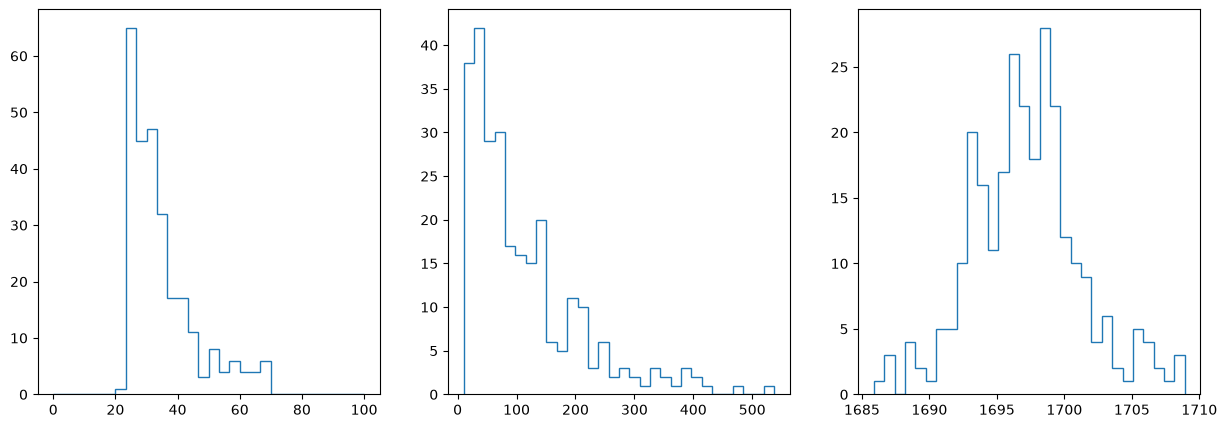

In [48]:
size = 5
rows = 1
cols = 3
nbins = 30

cuts = (mcp_baseline_RMS<3) & (djlgad_baseline_RMS<3) & (djlgad_amp<70) & (mcp_amp > 10) # & (trigger_baseline_RMS<3) 

print(np.sum(cuts))

fig, ax = plt.subplots(rows,cols, figsize = (cols*size, rows*size))

ax[0].hist(djlgad_amp [cuts], bins = nbins, histtype  = "step", range = (0, 100))
ax[1].hist(mcp_amp    [cuts], bins = nbins, histtype  = "step") #  range = (0,20))
ax[2].hist(trigger_amp[cuts], bins = nbins, histtype  = "step")

plt.show()
